In [78]:
from typing import TypedDict, Optional

class Candidate(TypedDict):
    id: str
    name: str
    skills: list[dict]
    experience: int
    role: str
    location: str

class JDMatchingState(TypedDict):
    jd_text: str
    jd_id: Optional[str]

    # For frontend
    primary_skills: list[str]
    experience_min: Optional[int]
    experience_max: Optional[int]
    role: Optional[str]
    location: Optional[str]

    # For matching
    matching_skills: list[dict]

    candidates: list[Candidate]
    matches: list[dict]

    business_decision: Optional[dict]

    errors: list[str]
    status: str

In [79]:
JD_UI_EXTRACTION_PROMPT = """
You are an expert Job Description information extraction system.

Analyze the Job Description below and extract ONLY the high-level information
required to display the job criteria in a talent matching application.

Return ONLY valid JSON.
Do NOT return Markdown.
Do NOT wrap the response in ```json or ```.
Do NOT add any explanation before or after the JSON.

Use EXACTLY this JSON structure:

{{
  "primary_skills": [],
  "experience_min": null,
  "experience_max": null,
  "role": null,
  "location": null
}}

## RULES

### primary_skills

Extract the most important high-level skills that should be displayed
to a recruiter/user as the primary requirements of the role.

- Return a simple array of strings.
- Prefer the most relevant technical/domain skills.
- Keep this list concise.
- Do not include every technology mentioned in the JD.
- Do not include generic soft skills such as communication or teamwork
  unless they are a major explicit requirement.
- Do not add skills that are not supported by the JD.
- Normalize obvious naming variations.

Examples:

"ReactJS" -> "React"
"Python programming" -> "Python"
"Microsoft Azure OpenAI Service" -> "Azure OpenAI"

Example:

"primary_skills": [
  "RAG",
  "Azure OpenAI",
  "Python",
  "LangGraph"
]

### experience_min

Extract the minimum required years of experience.

Examples:

"8+ years" -> 8

"5-10 years" -> 5

If not specified -> null

Return an integer or null.

### experience_max

Extract the maximum required years of experience.

Examples:

"8+ years" -> null

"5-10 years" -> 10

If not specified -> null

Return an integer or null.

### role

Extract the primary job title or role.

Return only the role name.

Example:

"Senior AI Solution Architect"

If unavailable, return null.

### location

Extract the required or preferred work location.

If multiple locations are mentioned, return them as a
comma-separated string.

If unavailable, return null.

## IMPORTANT

This extraction is for UI display only.

Do NOT attempt detailed candidate matching analysis here.

Do NOT generate skill justifications.

Do NOT create detailed skill categories.

Be conservative and use only information supported by the JD.

## JOB DESCRIPTION

{jd_text}
"""


JD_MATCHING_SKILLS_PROMPT = """
You are an expert HR Talent Acquisition analyst specializing in
technical skill extraction for candidate-to-job matching.

Analyze the Job Description below and extract the skills that should be
used for detailed candidate skill comparison.

Return ONLY valid JSON.
Do NOT return Markdown.
Do NOT wrap the response in ```json or ```.
Do NOT add any explanation before or after the JSON.

Use EXACTLY this JSON structure:

{{
  "matching_skills": [
    {{
      "skill": "string",
      "justification": "string"
    }}
  ]
}}

## PURPOSE

The output of this prompt will be passed directly into a downstream
candidate skill comparison process.

Therefore, extract a comprehensive set of specific skills that can
meaningly be compared against skills extracted from candidate resumes.

This is NOT the same as the high-level primary skills displayed in the UI.

## SKILL EXTRACTION RULES

Extract:

- Technical skills
- Programming languages
- Frameworks
- Libraries
- Platforms
- Cloud technologies
- AI/ML technologies
- Databases
- DevOps technologies
- Development tools
- Enterprise tools
- Domain-specific technologies
- Methodologies when they represent a meaningful professional skill
- Specific products or platforms explicitly required by the JD

For every skill return:

{{
  "skill": "normalized skill name",
  "justification": "why this skill is relevant to the role"
}}

## NORMALIZATION

Normalize obvious naming variations.

Examples:

"ReactJS" -> "React"

"React.js" -> "React"

"Python programming" -> "Python"

"Microsoft Azure OpenAI Service" -> "Azure OpenAI"

"Postgres" -> "PostgreSQL"

Do not duplicate equivalent skills.

## KEEP DISTINCT SKILLS SEPARATE

If the JD says:

"Python, FastAPI, PostgreSQL and Docker"

return:

[
  {{
    "skill": "Python",
    "justification": "..."
  }},
  {{
    "skill": "FastAPI",
    "justification": "..."
  }},
  {{
    "skill": "PostgreSQL",
    "justification": "..."
  }},
  {{
    "skill": "Docker",
    "justification": "..."
  }}
]

Do NOT combine them into one skill.

## JUSTIFICATION

The justification must explain why the skill is relevant to the JD.

Example:

{{
  "skill": "Cadence Virtuoso",
  "justification": "Required for analog and mixed-signal IC design and layout activities described in the role."
}}

The justification must be based on the JD.

Do not invent information.

## MATCHING GUIDELINES

Extract skills that can later be evaluated using:

1. Exact matching
2. Semantic matching
3. Technology-family relationships
4. Closely related technologies

However, do NOT automatically treat different tools as equivalent.

For example:

- React and React.js → same skill
- Python and Python programming → same skill
- AWS Lambda and AWS → related technology family
- JIRA and Azure DevOps → related purpose, but NOT the same skill

Preserve the specific technology whenever the JD explicitly requires it.

## GENERIC SKILLS

Do NOT include generic terms such as:

- Communication
- Teamwork
- Problem solving
- Leadership
- Microsoft Office

unless the JD clearly makes them a specific technical/professional
requirement relevant to the matching process.

## CONSERVATIVE EXTRACTION

Do not hallucinate skills.

A skill should be included only when:

- explicitly mentioned in the JD, OR
- strongly implied by a specific technical responsibility.

## QUALITY CHECK

Before returning the response:

- Remove duplicate skills.
- Normalize skill names.
- Preserve specific technologies.
- Ensure every skill has a meaningful justification.
- Ensure every skill is supported by the JD.
- Ensure the output is valid JSON.
- Return no text outside the JSON.

## JOB DESCRIPTION

{jd_text}
"""


def skill_fetch_prompt(resume_doc):
    return f"""
# RESUME SKILLS EXTRACTION PROMPT

## ROLE AND EXPERTISE
You are an elite Technical Recruiter and Skills Assessment Specialist with 20+ years of experience in talent acquisition, resume parsing, and competency mapping across all industries and job functions.

## TASK OBJECTIVE
Extract ALL skills mentioned explicitly in the provided resume with maximum granularity. For each skill identified, determine years of experience and provide clear justification for both the skill extraction and experience calculation.

## EXTRACTION GUIDELINES

### 1. SKILL IDENTIFICATION CRITERIA
Extract skills from the following resume sections with high precision:

#### Technical Skills
- Programming languages (Python, Java, C++, JavaScript, etc.)
- Frameworks and libraries (React, Django, TensorFlow, Spring Boot, etc.)
- Databases (MySQL, MongoDB, PostgreSQL, Redis, etc.)
- Cloud platforms (AWS, Azure, GCP, Oracle Cloud, etc.)
- DevOps tools (Docker, Kubernetes, Jenkins, Terraform, etc.)
- Operating systems (Linux, Windows, Unix, macOS, etc.)
- Software and tools (Git, JIRA, Tableau, PowerBI, SAP, etc.)
- Methodologies (Agile, Scrum, Kanban, Waterfall, etc.)

#### Domain Skills
- Industry-specific knowledge (Healthcare, Finance, E-commerce, etc.)
- Business domains (Supply Chain, CRM, ERP, Analytics, etc.)
- Certifications (AWS Certified, PMP, CISSP, CFA, etc.)

#### Soft Skills
- Only extract if EXPLICITLY mentioned (Leadership, Team Management, Communication, etc.)
- Do NOT infer soft skills from job descriptions

#### Professional Skills
- Project management
- Client management
- Vendor management
- Budget management
- Process improvement

### 2. EXPERIENCE CALCULATION METHODOLOGY

#### Primary Sources (in order of reliability):
1. **Explicit Duration Statements**: "5 years of Python experience"
2. **Skills Section with Duration**: "Python (4 years)"
3. **Job Timeline Analysis**: Calculate from employment dates where skill is mentioned
4. **Project Timeline**: If skill used in specific projects with dates
5. **Certification Dates**: Use as starting point if mentioned
6. **If duration is inferable from project, job role, or timeline, estimate conservatively and note how you inferred it in the justification.
7. **If there’s insufficient information, return "Unknown".

#### Calculation Rules:
- **If explicit duration given**: Use that exact duration
- **If mentioned in job role**: Calculate months/years between start and end dates of that position
- **If mentioned in multiple roles**: SUM the total duration across all roles
- **Overlapping periods**: Do NOT double-count overlapping timeframes
- **Current/ongoing roles**: Calculate up to present date (October 2025)
- **Education period**:
  - Count academic projects ONLY if skill explicitly mentioned
  - Reduce weightage by 50% (2 years academic = 1 year professional equivalent)
- **Certifications**: Count from certification date to present if actively used
- **No clear timeline**: Mark as "0.5" (minimal/mentioned only) with justification

#### Date Calculation Examples:
- Role: Jan 2020 - Dec 2022, Skills: Python, SQL → 3 years each
- Role 1: Jan 2020-Dec 2021 (Python), Role 2: Jun 2022-Present (Python) → 3.8 years total (not overlapping)
- "Currently working with React since 2023" → Calculate from 2023 to Oct 2025 = 2.8 years

### 3. JUSTIFICATION REQUIREMENTS

Each skill MUST include:

#### Justification Components:

**a) Source Location**: Where in resume the skill was found
- "Mentioned in Technical Skills section"
- "Listed under Job Role: Software Engineer at XYZ Corp"
- "Referenced in Project: E-commerce Platform Development"

**b) Context**: How the skill was mentioned
- "Used for backend development"
- "Led team using this technology"
- "Certified in this skill"
- "Part of daily responsibilities"

**c) Experience Calculation Logic**: Show the math
- "Calculated from employment duration: Jan 2020 - Dec 2022 = 3 years"
- "Explicitly stated: '5 years of experience with AWS'"
- "Sum of two roles: 2 years (Role A) + 1.5 years (Role B) = 3.5 years"
- "Mentioned in skills section without timeline, no usage in job roles = 0.5 years (basic familiarity)"

### 4. EXTRACTION RULES

#### DO:
- Extract EVERY skill mentioned, even if listed once
- Include variations (e.g., "JavaScript" and "JS" as same skill)
- Normalize skill names (e.g., "React.js" → "React")
- Count partial years (e.g., 2.5 years, 1.8 years)
- Be conservative with experience calculation when ambiguous
- Include tools, technologies, methodologies, and certifications

#### DO NOT:
- Infer skills not explicitly mentioned
- Extract company names, job titles, or educational degrees as skills
- Guess experience if no timeline information exists (use "Unknown")
- Include generic responsibilities as skills unless they represent specific competencies
- Double-count overlapping time periods

### 5. OUTPUT FORMAT

Return a valid JSON array with the following structure. Each dictionary must contain exactly three keys: skill, years_of_experience, and justification.

Example output structure:

[
  {{
    "skill": "Python",
    "years_of_experience": 5.5,
    "justification": "Found in Technical Skills section and mentioned in 3 job roles: (1) Software Engineer at ABC Corp (Jan 2020 - Dec 2022): 3 years, (2) Senior Developer at XYZ Inc (Jan 2023 - Present): 2.8 years (Jan 2023 to Oct 2025). Total: 5.8 years rounded to 5.5 due to 3-month gap between roles. Used for backend API development and data processing."
  }},
  {{
    "skill": "React",
    "years_of_experience": 2.0,
    "justification": "Explicitly stated in Technical Skills section as 'React (2 years)'. Also mentioned in current role at XYZ Inc where used for frontend development of customer portal since Jan 2023."
  }},
  {{
    "skill": "Agile Methodology",
    "years_of_experience": 4.0,
    "justification": "Mentioned across multiple roles: Software Engineer at ABC Corp (Jan 2020 - Dec 2022): 3 years working in Agile sprints, and current role at XYZ Inc (Jan 2023 - Present): 1 year as Scrum team member. Total: 4 years."
  }},
  {{
    "skill": "AWS Certified Solutions Architect",
    "years_of_experience": 1.5,
    "justification": "Certification obtained in April 2024 as listed in Certifications section. Currently utilizing AWS in present role at XYZ Inc since certification date. Calculated from Apr 2024 to Oct 2025 = 1.5 years."
  }},
  {{
    "skill": "Machine Learning",
    "years_of_experience": "Unknown",
    "justification": "Listed in Technical Skills section but no specific project or role mentions its usage. No timeline provided. Assigned minimum experience of 0.5 years indicating basic familiarity or theoretical knowledge."
  }}
]

### 6. EDGE CASES HANDLING

- **Skill mentioned without any dates**: Assign "Unknown" with justification
- **"Familiar with" or "Basic knowledge"**: Assign "Unknown"
- **"Expert" or "Advanced"**: Use timeline calculation, note proficiency in justification
- **Certifications without usage**: Count from certification date only
- **Academic projects**: Weight at 50% of actual time spent
- **Freelance/Contract work**: Count full duration if skill explicitly mentioned
- **Career breaks**: Do NOT count gap periods
- **Similar skills**: Treat as separate unless clearly identical (React vs React Native - separate)

### 7. QUALITY CHECKS

Before finalizing output, verify:
- Every entry has detailed justification with source reference
- Experience calculations are mathematically accurate
- No duplicates (skills are normalized)
- JSON format is valid and parseable
- All calculations account for current date: October 2025

## RESPONSE PROTOCOL
1. Analyze the entire resume systematically
2. Extract ALL skills meeting the criteria
3. Calculate experience using the methodology above
4. Provide detailed justification for each entry
5. Return ONLY the JSON array, no additional commentary

## CRITICAL REMINDERS
- Be EXHAUSTIVE - extract every skill mentioned
- Be PRECISE - show your calculation work
- Be CONSERVATIVE - when in doubt, use lower estimates with clear justification
- Be CONSISTENT - apply the same rules to all skills
- Current date for calculation purposes: October 2025

---

## INPUT RESUME
{resume_doc}"""


def extracted_skill_validator(resume_doc,extracted_skills_json):
    return f"""
## ROLE AND EXPERTISE
You are an expert Skills Validation Specialist and Quality Assurance Auditor with 15+ years of experience in resume analysis, data verification, and skills assessment accuracy. Your role is to validate extracted skills against the original resume to ensure accuracy, completeness, and proper justification.

## TASK OBJECTIVE
Validate the extracted skills JSON against the original resume. Verify each skill's presence, experience calculation accuracy, and justification quality. Return a corrected and validated JSON with the same structure, ensuring all entries are accurate and properly justified.

## VALIDATION PROCESS

### PHASE 1: PRESENCE VERIFICATION

For each skill in the extracted JSON:

#### Check 1: Skill Exists in Resume
- **Verify**: Is the skill explicitly mentioned in the resume?
- **Action**: If NOT found, REMOVE the skill entirely
- **Flag**: Skills that appear to be inferred or assumed

#### Check 2: Skill Name Accuracy
- **Verify**: Is the skill name correctly extracted and normalized?
- **Action**: Correct any misspellings or incorrect normalizations
- **Examples**:
  - "React.js" and "ReactJS" → Normalize to "React"
  - "AWS Lambda" mentioned but extracted as just "AWS" → Keep specific "AWS Lambda"

#### Check 3: Duplicate Detection
- **Verify**: Are there duplicate skills with different names?
- **Action**: Merge duplicates, sum non-overlapping experience
- **Examples**:
  - "JavaScript" and "JS" → Merge into "JavaScript"
  - "Machine Learning" and "ML" → Merge into "Machine Learning"

### PHASE 2: EXPERIENCE CALCULATION VALIDATION

#### Validation Rule 1: Explicit Duration Statements
- **Priority**: HIGHEST - Explicit statements override all calculations
- **Check**: If resume states "5 years of Python", JSON must show 5.0 years exactly
- **Action**: Correct to match explicit statement

#### Validation Rule 2: Job Timeline Calculations
- **Verify**: Date calculations are mathematically correct
- **Formula**: (End Date - Start Date) in years, accounting for months
- **Current Date**: Use October 2025 for ongoing roles
- **Precision**: Round to 1 decimal place (e.g., 2.8 years)

**Calculation Examples**:
- Job: Jan 2020 - Dec 2022 = 3.0 years
- Job: Mar 2021 - Aug 2023 = 2.4 years (29 months)
- Job: Jun 2023 - Oct 2025 = 2.3 years (28 months)
- Job: Jan 2020 - Present (Oct 2025) = 5.8 years (69 months)

#### Validation Rule 3: Multiple Role Aggregation
- **Check**: Sum experience across multiple roles correctly
- **Critical**: NO double-counting of overlapping periods
- **Action**: Identify overlaps and count shared time only once

**Overlap Detection Example**:

WRONG CALCULATION:
- Role A: Jan 2020 - Dec 2022 (Python) = 3.0 years
- Role B: Jun 2022 - Oct 2025 (Python) = 3.3 years
- Total claimed: 6.3 years (INCORRECT - double-counted Jun-Dec 2022)

CORRECT CALCULATION:
- Role A: Jan 2020 - May 2022 = 2.4 years
- Overlap: Jun 2022 - Dec 2022 = 0.6 years (count once)
- Role B: Jan 2023 - Oct 2025 = 2.8 years
- Total: 5.8 years

#### Validation Rule 4: Minimum Experience Assignment
- **"Unknown"**: Skill listed but zero context or timeline
- **0.5 years**: "Familiar with", "basic knowledge", or single mention without usage
- **Action**: Verify assignment matches resume context

#### Validation Rule 5: Academic/Certification Experience
- **Academic**: Apply 50% weight (2 years academic = 1 year professional)
- **Certifications**: Count from cert date ONLY if actively used in roles
- **Action**: Verify correct weightage applied

### PHASE 3: JUSTIFICATION QUALITY AUDIT

Each justification MUST contain:

1. **Source Location**: Exact section/role where skill appears
2. **Context**: How skill was used or applied
3. **Calculation**: Complete mathematical breakdown
4. **Multiple Sources**: All occurrences referenced if applicable

**POOR JUSTIFICATION (Reject)**:
- "Found in resume"
- "3 years experience"
- "Mentioned in job role"
- "Used for development"

**GOOD JUSTIFICATION (Accept)**:
- "Found in Technical Skills section and mentioned in Software Engineer role at ABC Corp (Jan 2020 - Dec 2022): 3 years. Used for backend API development with Django framework."
- "Explicitly stated in Technical Skills section as 'Python (5 years)'. Also mentioned in E-commerce Platform project description."
- "Mentioned across multiple roles: Software Engineer at ABC Corp (Jan 2020 - Dec 2022): 3 years working in Agile sprints, and current role at XYZ Inc (Jan 2023 - Present): 1.8 years as Scrum team member. Total: 4.8 years."

### PHASE 4: COMPLETENESS CHECK

Scan the original resume for missing skills:

**Check These Sections**:
- Technical Skills / Core Competencies
- Job responsibilities and bullet points
- Project descriptions
- Certifications and training
- Tools mentioned in achievements
- Methodologies explicitly stated

**Action**: Add missing skills with proper calculation and justification

### PHASE 5: FALSE POSITIVE ELIMINATION

Remove these if extracted as skills:

- Job titles (Software Engineer, Project Manager)
- Company names (Google, Microsoft) unless specific tech (Google Cloud Platform)
- Educational degrees (Bachelor's in CS, MBA)
- Generic phrases (worked on projects, collaborated with team)
- Inferred soft skills (leadership inferred from "led team" without explicit mention)
- Industry names (Healthcare, Finance) unless domain expertise explicitly stated

### PHASE 6: EDGE CASE VALIDATION

#### Career Gaps
- **Rule**: Gap periods are NOT counted
- **Example**: Role ends Dec 2020, next starts Jun 2021 → 6-month gap excluded

#### Concurrent Roles
- **Rule**: Overlapping time counted once per skill
- **Example**: Two simultaneous jobs using Python → count overlapping months once

#### Skill Variations
- **Keep Separate**: React vs React Native, Java vs JavaScript, SQL vs MySQL
- **Merge**: JavaScript vs JS, React.js vs React, ML vs Machine Learning

#### Proficiency Levels
- **Rule**: Note in justification but don't alter calculation
- **Example**: "Expert in Python" → include "Proficiency level: Expert" in justification

## OUTPUT FORMAT

Return a valid JSON array with the following structure. Each dictionary must contain exactly three keys: skill, years_of_experience, and justification.

**CRITICAL**: Use double curly braces `{{` and `}}` for JSON objects to ensure proper formatting.

Example output structure:
```json
[
  {{
    "skill": "Python",
    "years_of_experience": 5.5,
    "justification": "Found in Technical Skills section and mentioned in 3 job roles: (1) Software Engineer at ABC Corp (Jan 2020 - Dec 2022): 3 years, (2) Senior Developer at XYZ Inc (Jan 2023 - Present): 2.8 years (Jan 2023 to Oct 2025). Total: 5.8 years rounded to 5.5 due to 3-month gap between roles. Used for backend API development and data processing."
  }},
  {{
    "skill": "React",
    "years_of_experience": 2.0,
    "justification": "Explicitly stated in Technical Skills section as 'React (2 years)'. Also mentioned in current role at XYZ Inc where used for frontend development of customer portal since Jan 2023."
  }},
  {{
    "skill": "Agile Methodology",
    "years_of_experience": 4.0,
    "justification": "Mentioned across multiple roles: Software Engineer at ABC Corp (Jan 2020 - Dec 2022): 3 years working in Agile sprints, and current role at XYZ Inc (Jan 2023 - Present): 1 year as Scrum team member. Total: 4 years."
  }},
  {{
    "skill": "AWS Certified Solutions Architect",
    "years_of_experience": 1.5,
    "justification": "Certification obtained in April 2024 as listed in Certifications section. Currently utilizing AWS in present role at XYZ Inc since certification date. Calculated from Apr 2024 to Oct 2025 = 1.5 years."
  }},
  {{
    "skill": "Docker",
    "years_of_experience": "Unknown",
    "justification": "Listed in Technical Skills section but no specific project or role mentions its usage. No timeline provided. Indicates basic familiarity or theoretical knowledge."
  }}
]


---


VALIDATION CORRECTIONS APPLIED:
1. REMOVED: "Software Engineer" - Job title, not a skill
2. CORRECTED: Python experience 6.5 → 5.5 years - Removed 1-year overlap between roles (Jun 2022 - Jun 2023)
3. ADDED: "Docker" - Found in Technical Skills section but missing from extraction
4. MERGED: "JavaScript" and "JS" into single "JavaScript" entry, combined experience: 4.2 years
5. UPDATED: "Machine Learning" from 0.5 → "Unknown" - Listed in skills but no usage context in roles or projects
6. CORRECTED: AWS calculation error - Jan 2021 to Oct 2025 = 4.8 years (was incorrectly shown as 5.0)
7. ENHANCED: React justification - Added specific project reference "Customer Portal" from resume
8. CORRECTED: Agile Methodology - Fixed double-counting overlap, adjusted from 5.0 to 4.0 years


CRITICAL VALIDATION RULES
1. Source of Truth: Original resume is ALWAYS correct; JSON may contain errors
2. Mathematical Precision: Verify all date calculations with calculator
3. Conservative Approach: When ambiguous, use lower estimate with clear reasoning
4. Completeness Priority: Actively search for missing skills, don't just validate existing
5. Quality over Quantity: 20 accurate skills > 30 questionable ones
6. Explicit > Calculated: Explicit duration statements override timeline calculations
7. Zero Tolerance: Remove any skill not explicitly in resume
8. Format Consistency: Use double curly braces {{}} in JSON output

RESPONSE PROTOCOL
1. Read original resume thoroughly
2. Validate each extracted skill against resume
3. Identify and add missing skills from resume
4. Correct all calculation errors
5. Remove false positives
6. Return: Validated JSON array + Corrections Report


INPUT DATA
ORIGINAL RESUME:
{resume_doc}
EXTRACTED SKILLS JSON:
{extracted_skills_json}"""



def skill_type_classification(validated_skills):
    return f"""# SYSTEM ROLE
You are an expert Skills Taxonomy Classifier specializing in resume analysis and candidate evaluation.

# TASK
Classify each skill in the provided list as either "Technical" or "Non-Technical" by adding a `skill_class` key to each dictionary entry.

# INPUT FORMAT
You will receive a list of dictionaries, where each dictionary contains:
- `skill`: Name of the skill
- `years_of_experience`: Duration of experience with the skill
- `justification`: Context explaining why this skill was identified

# CLASSIFICATION CRITERIA

## Technical Skills
Skills that involve:
- Programming languages (Python, Java, C++, JavaScript, etc.)
- Software frameworks and libraries (React, Django, TensorFlow, etc.)
- Database technologies (SQL, MongoDB, PostgreSQL, etc.)
- Cloud platforms (AWS, Azure, GCP, etc.)
- DevOps and infrastructure tools (Docker, Kubernetes, Jenkins, etc.)
- Data science and analytics tools (Pandas, R, Tableau, Power BI, etc.)
- Operating systems and networking technologies
- Hardware and electronics knowledge
- Engineering tools (CAD, MATLAB, AutoCAD, etc.)
- Cybersecurity tools and methodologies
- Mobile development platforms (iOS, Android, Flutter, etc.)
- Version control systems (Git, SVN, etc.)
- Testing frameworks and tools
- API technologies (REST, GraphQL, SOAP, etc.)
- Any domain-specific technical expertise

## Non-Technical Skills
Skills that involve:
- Communication (written, verbal, presentation, etc.)
- Leadership and management
- Interpersonal abilities (teamwork, collaboration, networking, etc.)
- Organizational skills (time management, project management, planning, etc.)
- Creative abilities (design thinking, creativity, content creation, etc.)
- Sales and marketing
- Customer service and relationship management
- Problem-solving and critical thinking (when not technical in nature)
- Adaptability and flexibility
- Emotional intelligence
- Negotiation and conflict resolution
- Business acumen and strategy
- Language proficiencies

# OUTPUT REQUIREMENTS

1. **Preserve All Input Data**: Return the EXACT same structure with all original keys and values intact
2. **Add Classification**: Include ONLY one new key: `skill_class` with value "Technical" or "Non-Technical"
3. **Strict JSON Format**: Output must be valid JSON
4. **No Modifications**: Do NOT alter, summarize, or skip any existing data
5. **Complete Processing**: Classify ALL skills in the input list

# OUTPUT FORMAT
```json
[
  {{
    "skill": "<original_skill_name>",
    "years_of_experience": <original_years>,
    "justification": "<original_justification>",
    "skill_class": "Technical" | "Non-Technical"
  }},
  ...
]
```

# EDGE CASES
- **Hybrid Skills** (e.g., "Technical Writing", "Data Analysis"): If the skill has technical components or requires technical knowledge, classify as "Technical"
- **Tools for Non-Technical Work** (e.g., "Microsoft Word", "Email"): Classify as "Non-Technical"
- **Unclear Skills**: Use the justification field to inform classification
- **Domain-Specific Skills**: Consider the technical vs. business nature (e.g., "Financial Modeling" with Excel = Technical)

# INSTRUCTIONS
1. Read the entire input list
2. Analyze each skill based on the criteria above
3. Add the `skill_class` key with appropriate value
4. Return the complete JSON with all original data preserved
5. Ensure valid JSON syntax (proper quotes, commas, brackets)

# EXAMPLE

**Input:**
```json
[
  {{
    "skill": "Python",
    "years_of_experience": 5,
    "justification": "Developed multiple backend services using Python and Django framework"
  }},
  {{
    "skill": "Team Leadership",
    "years_of_experience": 3,
    "justification": "Led a team of 8 developers in agile sprints"
  }}
]
```

**Output:**
```json
[
  {{
    "skill": "Python",
    "years_of_experience": 5,
    "justification": "Developed multiple backend services using Python and Django framework",
    "skill_class": "Technical"
  }},
  {{
    "skill": "Team Leadership",
    "years_of_experience": 3,
    "justification": "Led a team of 8 developers in agile sprints",
    "skill_class": "Non-Technical"
  }}
]
```

# CRITICAL REMINDERS
- Output ONLY the JSON array, no additional text or explanation
- Maintain exact spelling, capitalization, and formatting from input
- Process every single entry without exception
- Validate JSON syntax before returning


INPUT DATA
EXTRACTED SKILLS JSON:
{validated_skills}""

"""

def compare_skills(candidate_skills,jd_skills):
    return f"""You are an expert HR Talent Acquisition analyst specializing in precise skills matching and assessment. Your task is to perform a comprehensive comparison between candidate skills and job requirements.

  ## INPUT DATA

  **Candidate Skills:**
  {candidate_skills}

  **Job Description Skills:**
  {jd_skills}

  ## YOUR TASK

  Analyze both inputs and identify ALL skills that match between the candidate's resume and the job description. For each match, provide detailed justification.

  ## MATCHING CRITERIA

  1. **Exact Match**: Skill names are identical (case-insensitive)
  2. **Semantic Match**: Skills are synonymous or closely related (e.g., "Python Programming" = "Python", "Machine Learning" = "ML")
  3. **Technology Family Match**: Skills belong to the same technology ecosystem (e.g., "AWS Lambda" matches "AWS Services", "React" matches "React.js")
  4. **Tool Suite Match**: Different tools serving the same purpose (e.g., "JIRA" and "Azure DevOps" both for Agile project management)

  ## OUTPUT FORMAT

  Provide your analysis in the following JSON structure:
  ```json
  {{
    "matching_summary": {{
      "total_jd_skills": <number>,
      "total_candidate_skills": <number>,
      "exact_matches": <number>,
      "semantic_matches": <number>,
      "technology_family_matches": <number>,
      "total_matches": <number>,
      "match_percentage": <percentage>
    }},
    "matched_skills": [
      {{
        "jd_skill": "<skill name from JD>",
        "candidate_skill": "<corresponding skill name from resume>",
        "match_type": "exact|semantic|technology_family",
        "candidate_experience_years": <years>,
        "jd_justification": "<why this skill matters for the role>",
        "candidate_justification": "<how candidate demonstrates this skill>",
        "match_strength": "strong|moderate|weak",
        "match_reasoning": "<explain why these skills match>"
      }}
    ],
    "unmatched_jd_skills": [
      {{
        "skill": "<skill from JD not found in resume>",
        "justification": "<why this skill is required>",
        "criticality": "critical|important|nice-to-have"
      }}
    ],
    "additional_candidate_skills": [
      {{
        "skill": "<skill in resume not mentioned in JD>",
        "years_of_experience": <years>,
        "potential_value": "<how this skill might benefit the role>"
      }}
    ],
    "assessment_insights": {{
      "strengths": ["<key strength areas>"],
      "gaps": ["<critical skill gaps>"],
      "transferable_skills": ["<skills that could compensate for gaps>"],
      "overall_fit_score": "<0-100>",
      "recommendation": "<brief hiring recommendation>"
    }}
  }}
  ```

  ## MATCHING GUIDELINES

  - **Be thorough**: Don't miss related skills just because names differ slightly
  - **Consider context**: Use the justifications provided to understand skill depth
  - **Weight experience**: Factor in years of experience when assessing match strength
  - **Think holistically**: Consider how skills complement each other
  - **Be fair**: Give credit for equivalent or superior alternatives (e.g., PostgreSQL experience counts toward SQL database skills)
  - **Industry awareness**: Recognize industry-standard equivalents (e.g., Git/GitHub/GitLab/Bitbucket)

  ## SPECIAL CONSIDERATIONS

  1. If a candidate has a **more advanced version** of a skill (e.g., JD asks for "Python", candidate has "Advanced Python & Machine Learning"), count it as a strong match
  2. If a candidate has **broader ecosystem knowledge** (e.g., JD asks for "React", candidate has "React, Redux, Next.js"), note this as a strength
  3. For **version-specific tools** (e.g., "Python 3.x"), be flexible with minor version differences
  4. Consider **recency**: More recent experience is more valuable
  5. **Project vs Professional experience**: Note when skills come from projects (weighted lower) vs professional roles

  ## QUALITY CHECKS

  Before finalizing output:
  - Have I checked for all possible semantic matches?
  - Have I considered technology families and ecosystems?
  - Have I been fair in recognizing equivalent skills?
  - Is my match_strength assessment justified?
  - Have I provided actionable insights?

  ```
  """

In [80]:
def extract_jd(state):
    jd_text = state["jd_text"]

    try:
        status = "JD_EXTRACTING"

        prompt = JD_UI_EXTRACTION_PROMPT.format(jd_text=jd_text)
        print("prompt extracted")
        extracted = model.generate_json(prompt)
        status = "JD_EXTRACTED"
        print("extracted", extracted)

        prompt = JD_MATCHING_SKILLS_PROMPT.format(jd_text=state["jd_text"])
        print("prompt2 done")
        result = model.generate_json(prompt)
        print("result",result)
        status = "JD_SKILLS_EXTRACTED"

        return {
            "primary_skills": extracted.get("primary_skills", []),
            "experience_min": extracted.get("experience_min"),
            "experience_max": extracted.get("experience_max"),
            "role": extracted.get("role"),
            "location": extracted.get("location"),
            "matching_skills": result.get("matching_skills", []),
            "status": status,
        }

    except Exception as exc:
        print(status)
        raise Exception(f"Error in extract_jd: {exc}")
        print(f"Error in extract_jd: {exc}")

        return {
            "errors": [str(exc)],
            "status": "FAILED AT EXTRACTING JD",
        }

In [81]:
def validate_jd(state):
    print("validating",state)
    errors = []

    if not state["primary_skills"]:
        errors.append("No primary skills could be extracted from the JD for UI display.")

    if not state["matching_skills"]:
        errors.append("No matching skills could be extracted from the JD for detailed comparison.")

    if not state["role"]:
        errors.append("Role could not be identified.")

    if state["experience_min"] is not None:
        if state["experience_min"] < 0:
            errors.append("Invalid minimum experience.")

    if errors:
        return {
            "errors": errors,
            "status": "VALIDATION_FAILED",
        }

    return {
        "status": "JD_VALIDATED",
    }

In [82]:
# def fetch_candidates(state):
#     candidates = get_candidates()

#     return {
#         "candidates": candidates,
#         "status": "CANDIDATES_LOADED",
#     }

def fetch_candidates(state):
    print("fetching", state)
    candidates = [
        {
            "sap_id": "100001",
            "name": "Mallikarjuna Patil",
            "skills": [
                {
                    "skill": "RAG",
                    "justification": "Experience building retrieval-augmented generation solutions."
                },
                {
                    "skill": "Azure OpenAI",
                    "justification": "Hands-on experience with Azure OpenAI services."
                },
                {
                    "skill": "Python",
                    "justification": "Strong experience developing AI solutions using Python."
                },
            ],
            "experience": 13,
            "role": "AI Solution Lead",
            "location": "Bangalore",
            "status": "Available",
        },
        {
            "sap_id": "100004",
            "name": "Siddesh",
            "skills": [
                {
                    "skill": "FastAPI",
                    "justification": "Experience developing Python-based REST APIs."
                },
                {
                    "skill": "RAG",
                    "justification": "Experience implementing retrieval-augmented generation pipelines."
                },
                {
                    "skill": "LangGraph",
                    "justification": "Experience building agentic AI workflows using LangGraph."
                },
            ],
            "experience": 10,
            "role": "AI Engineer",
            "location": "Bangalore",
            "status": "In Pipeline",
        },
    ]

    return {
        "candidates": candidates,
        "status": "CANDIDATES_LOADED",
    }

In [83]:
def match_candidates(state):
    print("matching", state)
    matches = []

    jd_skills = state["matching_skills"]

    for candidate in state["candidates"]:

        candidate_skills = candidate.get("skills", [])

        prompt = compare_skills(
            candidate_skills=candidate_skills,
            jd_skills=jd_skills,
        )

        result = model.generate_json(prompt)

        assessment = result.get("assessment_insights", {})
        summary = result.get("matching_summary", {})

        matches.append({
            "sap_id": candidate["sap_id"],
            "name": candidate["name"],
            "skills": candidate_skills,
            "status": candidate.get("status"),

            "match_score": int(
                assessment.get("overall_fit_score", 0)
            ),

            "match_percentage": summary.get(
                "match_percentage", 0
            ),

            "reasoning": assessment.get(
                "recommendation", ""
            ),

            "skill_analysis": result,
        })

    return {
        "matches": matches,
        "status": "MATCHING_COMPLETED",
    }


In [84]:
def rank_candidates(state):
    print("ranking", state)
    matches = sorted(
        state["matches"],
        key=lambda item: item["match_score"],
        reverse=True,
    )

    for index, match in enumerate(matches, start=1):
        match["rank"] = index

    return {
        "matches": matches,
        "status": "MATCHES_RANKED",
    }

In [85]:
def business_decision(state):
    print("business_decision", state)
    matches = state["matches"]

    available = [
        match
        for match in matches
        if match["status"] == "Available"
    ]


    return {
        "business_decision": {
            "supported": len(matches) > 0,
            "recommendation": (
                "Prioritize available talent; "
                "retain in-pipeline profiles as clearly flagged."
                if available
                else "No immediately available candidates found."
            ),
        },
        "status": "COMPLETED",
    }

In [86]:
import json
import os
from google.colab import userdata

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()


class LLMService:

    def __init__(self):
        # Retrieve the API key from Colab's secrets manager
        openai_api_key = userdata.get("OPENAI_API_KEY")
        if not openai_api_key:
            raise ValueError("OPENAI_API_KEY not found in Colab secrets. Please set it in the '🔑' panel.")

        self.llm = ChatOpenAI(
            model="gpt-4o-mini",
            temperature=0,
            api_key=openai_api_key  # Pass the API key explicitly
        )

    def invoke(self, prompt: str) -> str:
        response = self.llm.invoke(prompt)
        return response.content

    def generate_json(self, prompt: str) -> dict:
        response = self.llm.invoke(prompt)

        content = str(response.content)

        # Clean markdown fences if returned
        content = content.replace("```json", "")
        content = content.replace("```", "")
        content = content.strip()

        return json.loads(content)


model = LLMService()

JD Matching graph compiled successfully.


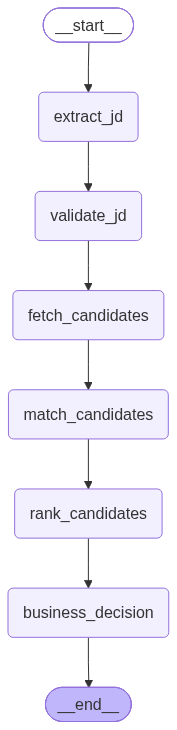

In [87]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(JDMatchingState)

# Nodes
graph.add_node("extract_jd", extract_jd)
graph.add_node("validate_jd", validate_jd)
graph.add_node("fetch_candidates", fetch_candidates)
graph.add_node("match_candidates", match_candidates)
graph.add_node("rank_candidates", rank_candidates)
graph.add_node("business_decision", business_decision)

# Flow
graph.add_edge(START, "extract_jd")
graph.add_edge("extract_jd", "validate_jd")
graph.add_edge("validate_jd", "fetch_candidates")
graph.add_edge("fetch_candidates", "match_candidates")
graph.add_edge("match_candidates", "rank_candidates")
graph.add_edge("rank_candidates", "business_decision")
graph.add_edge("business_decision", END)



jd_matching_graph = graph.compile()

print("JD Matching graph compiled successfully.")
jd_matching_graph

In [88]:
jd = """Job Title: AI Solution Lead

Location: Bangalore

Experience: 10–14 years

Job Description:

We are looking for an experienced AI Solution Lead to design and deliver
enterprise Generative AI solutions.

Key Responsibilities:
- Design and implement Retrieval-Augmented Generation (RAG) solutions.
- Build enterprise AI applications using Azure OpenAI.
- Develop AI solutions and backend services using Python.
- Lead the architecture and implementation of scalable GenAI solutions.
- Work with stakeholders to translate business requirements into AI solutions.
- Experience with AI agents and agentic workflows is desirable.
- Experience with FastAPI or similar Python backend frameworks is a plus.

Required Skills:
- RAG
- Azure OpenAI
- Python
- Generative AI
- AI Solution Architecture
- Enterprise AI

Preferred Skills:
- LangGraph
- FastAPI
- AI Agents

Location: Bangalore"""
initial_state = {
    "jd_text": jd,
    "jd_id": None,

    "primary_skills": [],
    "experience_min": None,
    "experience_max": None,
    "role": None,
    "location": None,

    "matching_skills": [],

    "candidates": [],
    "matches": [],

    "business_decision": None,

    "errors": [],
    "status": "STARTED",
}

result = jd_matching_graph.invoke(
    initial_state,
    config={
        "configurable": {
            "thread_id": "test-jd-001"
        }
    }
)

print(result)

prompt extracted
extracted {'primary_skills': ['RAG', 'Azure OpenAI', 'Python', 'Generative AI', 'AI Solution Architecture', 'Enterprise AI'], 'experience_min': 10, 'experience_max': 14, 'role': 'AI Solution Lead', 'location': 'Bangalore'}
prompt2 done
result {'matching_skills': [{'skill': 'RAG', 'justification': 'Required for designing and implementing Retrieval-Augmented Generation solutions.'}, {'skill': 'Azure OpenAI', 'justification': 'Explicitly required for building enterprise AI applications.'}, {'skill': 'Python', 'justification': 'Necessary for developing AI solutions and backend services.'}, {'skill': 'Generative AI', 'justification': 'Core focus of the role, as the position involves designing and delivering Generative AI solutions.'}, {'skill': 'AI Solution Architecture', 'justification': 'Relevant for leading the architecture and implementation of scalable GenAI solutions.'}, {'skill': 'Enterprise AI', 'justification': 'Required for developing AI solutions that meet enterp

In [89]:
result.get

<function dict.get(key, default=None, /)>